# Đánh giá hiệu năng bộ thu thập

:::{note}
Báo cáo đang ở trạng thái **khung mẫu đề cương**. Toàn bộ các bảng và biểu đồ hiệu năng trong chương này được kết nối trực tiếp với lược đồ `report_book/data/m1_benchmark.json`. Các trường số liệu hiện hiển thị ở trạng thái chờ kết xuất nhật ký đo lường thực tế từ máy ảo Google Colab ở chế độ CPU.
:::


## 1. Môi trường và phương pháp đo (`Benchmark Metrics v2`)

Theo yêu cầu của đề bài, bài kiểm tra hiệu năng chuẩn mực được tiến hành trên máy ảo Google Colab ở chế độ CPU:
- Bộ xử lý: 2 vCPU Intel Xeon tốc độ 2,20 GHz.
- Bộ nhớ RAM: 12,67 GB.
- Không gian ổ đĩa: 107,72 GB.
- Hệ điều hành và môi trường: Ubuntu 22.04 LTS, Python 3.10+.

### Kiến trúc bộ đo `src.benchmark_runner` và `src.benchmark_metrics`

Hệ thống đo kiểm kết nối trực tiếp bộ điều phối lô `BatchRunner` với động cơ lấy mẫu tài nguyên `benchmark_pipeline()` thông qua hai hàm giao diện chính là `run_benchmark()` và `aggregate_batch()`:
1. Lấy mẫu tài nguyên hai luồng độc lập:
   - Lấy mẫu bộ nhớ RAM (`sample_interval = 0.1` giây): Định kỳ mỗi 0,1 giây (kèm hai điểm đo sát đầu và cuối tiến trình), bộ đo ghi nhận tổng mức tiêu thụ RSS của tiến trình Python hiện tại và toàn bộ các tiến trình con quan sát được thông qua thư viện `psutil` (hoặc cơ chế dự phòng `/proc/self/statm` trên Linux).
   - Lấy mẫu dung lượng đĩa (`disk_interval = 30.0` giây): Chạy trên một tiểu trình riêng biệt định kỳ mỗi 30 giây để không làm trễ nhịp lấy mẫu RAM 0,1 giây. Tại mỗi lần quét, bộ đo tính tổng dung lượng logic (logical bytes) của các tệp thường trong danh sách thư mục giám sát `disk_roots`.
2. Phạm vi đo đĩa và thư mục giải nén tạm (`TMPDIR`): Do bộ tải nguồn lưu tệp nén tải về trong thư mục tạm `TEMP` trước khi lọc các tệp `.tex` và `.bib` vào `corpus_root`, việc đo trọn vẹn dung lượng đĩa đỉnh khi chạy trên Colab được thực hiện bằng cách trỏ biến môi trường `TMPDIR` vào một thư mục nháp riêng (`scratch_root`) và truyền `disk_roots = [corpus_root, scratch_root]`. Dung lượng dữ liệu đầu ra cuối cùng (`final_corpus_bytes`) vẫn được đo tách biệt riêng trên `corpus_root` tại lần quét cuối.
3. Định nghĩa toán học của các chỉ số thời gian:
   - Thời gian toàn bộ quy trình (`wall_seconds`): Đo bằng đồng hồ `perf_counter` bao quanh toàn bộ lượt gọi Batch (gồm khởi tạo lô, kiểm tra điểm kiểm soát, chờ giãn cách 3,0 giây, thử lại và ghi nhật ký).
   - Thời gian khám phá (`discovery_wall_seconds`): Tổng thời gian thực tế tiêu tốn quanh hàm `query_arxiv()`, bao gồm chờ bộ điều tiết tốc độ, thử lại mạng và bóc tách Atom XML (các lượt đọc từ bộ nhớ đệm được tính 0 giây).
   - Thời gian trung bình mỗi bài báo (`average_paper_seconds`): Tổng thời gian xử lý từng bài báo qua các phiên chia cho tổng số vị trí ID ứng viên duy nhất trong tập được chọn (bao gồm cả các vị trí `not_found` hoặc lỗi).

### Phương pháp luận ghép nối và tổng hợp nhiều phiên Colab (`aggregate_batch`)

Với quy mô 20.000 vị trí ID, tiến trình chạy trên Google Colab miễn phí (giới hạn tối đa 12 giờ mỗi phiên) được chia thành $K$ phiên thực thi tuần tự. Ở mỗi phiên thứ $i$ (ứng với một `attempt_id`), hệ thống lưu bền vững một tệp đo lường phụ trợ tại `<log_root>/<batch_id>/measurements/<attempt_id>.json` cùng bộ ba tệp `intent.json`, `resources.json` và `report.json`. Hàm `aggregate_batch()` tổng hợp kết quả toàn cục qua $K$ phiên hợp lệ theo các công thức chuẩn xác sau:

1. Tổng thời gian thực thi toàn cục (`wall_seconds`): Cộng dồn thời gian thực thi thực tế của từng phiên mà không tính khoảng thời gian nghỉ giữa các phiên:
$$T_{\text{total}} = \sum_{i=1}^{K} T_i$$
2. Mức tiêu thụ RAM trung bình toàn cục (`ram.average_bytes`): Tính bằng trung bình có trọng số theo tổng số mẫu hợp lệ $N_i$ thu thập được ở từng phiên (tuyệt đối không lấy trung bình cộng giản đơn của các số trung bình phiên):
$$\overline{\text{RAM}}_{\text{total}} = \frac{\sum_{i=1}^{K} \text{sum\_sample\_bytes}_i}{\sum_{i=1}^{K} N_i}$$
3. Mức RAM đỉnh và Đĩa đỉnh toàn cục (`sampled_peak_bytes`): Lấy giá trị cực đại trên toàn bộ các phiên có cùng phạm vi đo:
$$\text{Peak}_{\text{total}} = \max_{1 \le i \le K} \left( \text{Peak}_i \right)$$
4. Dung lượng dữ liệu đầu ra cuối cùng (`final_corpus_bytes`): Lấy trực tiếp giá trị đo `final_corpus_bytes` tại phiên hoàn tất cuối cùng $K$, đồng thời đối chiếu chéo với tổng dung lượng tệp hợp lệ (`verified_source_bytes`) qua bảng mã băm SHA256 trong `CorpusStorage`.


In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt

with open("../data/m1_benchmark.json", "r", encoding="utf-8") as f:
    bench = json.load(f)

is_placeholder = bench.get("is_placeholder", False)
t_metrics = bench["time_metrics"]
m_metrics = bench["memory_metrics"]
s_metrics = bench["storage_metrics"]

def fmt_b(val, unit="", factor=1.0, fmt_spec=".2f"):
    if is_placeholder or val is None:
        return "-- (chờ đo kiểm trên Colab)"
    scaled = val * factor
    return f"{scaled:{fmt_spec}} {unit}"

bench_df = pd.DataFrame([
    {"Nhóm chỉ số": "1. Thời gian", "Chỉ số đo theo yêu cầu đề bài": "Thời gian xử lý một bài báo đơn lẻ (Single Paper Latency)", "Giá trị thực nghiệm": fmt_b(t_metrics.get('single_paper_wall_time_seconds'), 'giây')},
    {"Nhóm chỉ số": "1. Thời gian", "Chỉ số đo theo yêu cầu đề bài": "Thời gian trung bình mỗi bài báo (Average time per paper)", "Giá trị thực nghiệm": fmt_b(t_metrics['avg_wall_time_per_paper_seconds'], 'giây')},
    {"Nhóm chỉ số": "1. Thời gian", "Chỉ số đo theo yêu cầu đề bài": "Thời gian trung bình mỗi phiên bản (Average time per version)", "Giá trị thực nghiệm": fmt_b(t_metrics['avg_wall_time_per_version_seconds'], 'giây')},
    {"Nhóm chỉ số": "1. Thời gian", "Chỉ số đo theo yêu cầu đề bài": "Tổng thời gian khám phá bài báo (Discovery total wall time)", "Giá trị thực nghiệm": fmt_b(t_metrics['discovery_total_wall_time_seconds'], 'giây')},
    {"Nhóm chỉ số": "1. Thời gian", "Chỉ số đo theo yêu cầu đề bài": "Tổng thời gian toàn bộ quy trình (End-to-end wall time)", "Giá trị thực nghiệm": fmt_b(t_metrics['total_end_to_end_wall_time_seconds'], 'giây')},
    {"Nhóm chỉ số": "2. Bộ nhớ RAM", "Chỉ số đo theo yêu cầu đề bài": "Mức RAM đỉnh khi thực thi (Maximum peak RAM)", "Giá trị thực nghiệm": fmt_b(m_metrics['peak_ram_mb'], 'MB', fmt_spec=".1f")},
    {"Nhóm chỉ số": "2. Bộ nhớ RAM", "Chỉ số đo theo yêu cầu đề bài": "Mức RAM trung bình theo mẫu (Average sampled RAM)", "Giá trị thực nghiệm": fmt_b(m_metrics['avg_ram_mb'], 'MB', fmt_spec=".1f")},
    {"Nhóm chỉ số": "3. Lưu trữ", "Chỉ số đo theo yêu cầu đề bài": "Dung lượng đĩa tối đa khi chạy (Maximum disk storage)", "Giá trị thực nghiệm": fmt_b(s_metrics['max_disk_usage_gb'], 'GB')},
    {"Nhóm chỉ số": "3. Lưu trữ", "Chỉ số đo theo yêu cầu đề bài": "Dung lượng dữ liệu đầu ra cuối cùng (Final corpus output)", "Giá trị thực nghiệm": fmt_b(s_metrics['final_corpus_output_gb'], 'GB')}
])

bench_df.style.hide(axis="index").set_caption("Bảng 1.2: Bảng chỉ số hiệu năng chuẩn mực trên Google Colab ở chế độ CPU (Đầy đủ 7 chỉ số theo đề bài)")


Nhóm chỉ số,Chỉ số đo theo yêu cầu đề bài,Giá trị thực nghiệm
1. Thời gian,Thời gian xử lý một bài báo đơn lẻ (Single Paper Latency),-- (chờ đo kiểm trên Colab)
1. Thời gian,Thời gian trung bình mỗi bài báo (Average time per paper),-- (chờ đo kiểm trên Colab)
1. Thời gian,Thời gian trung bình mỗi phiên bản (Average time per version),-- (chờ đo kiểm trên Colab)
1. Thời gian,Tổng thời gian khám phá bài báo (Discovery total wall time),-- (chờ đo kiểm trên Colab)
1. Thời gian,Tổng thời gian toàn bộ quy trình (End-to-end wall time),-- (chờ đo kiểm trên Colab)
2. Bộ nhớ RAM,Mức RAM đỉnh khi thực thi (Maximum peak RAM),-- (chờ đo kiểm trên Colab)
2. Bộ nhớ RAM,Mức RAM trung bình theo mẫu (Average sampled RAM),-- (chờ đo kiểm trên Colab)
3. Lưu trữ,Dung lượng đĩa tối đa khi chạy (Maximum disk storage),-- (chờ đo kiểm trên Colab)
3. Lưu trữ,Dung lượng dữ liệu đầu ra cuối cùng (Final corpus output),-- (chờ đo kiểm trên Colab)


## 2. Phân bổ thời gian xử lý và bóc tách thành phần

Để phản ánh trung thực độ trễ vận hành thực tế theo đồng hồ đo, toàn bộ thời gian chờ giãn cách 3,0 giây giữa các yêu cầu và thời gian thử lại khi gặp lỗi mạng đều được tính vào tổng thời gian chạy của hệ thống theo đúng quy chuẩn đo kiểm hiệu năng.

Thời gian xử lý của hệ thống được bóc tách thành hai thành phần chính:
1. Thời gian chờ mạng và kiểm soát tần suất: Bao gồm khoảng nghỉ 3,0 giây bắt buộc giữa các yêu cầu đến máy chủ arXiv và thời gian chờ của giải thuật Backoff hàm mũ khi máy chủ báo bận. Thành phần này chiếm tỷ trọng chi phối (ước tính trên 85% tổng thời gian chạy).
2. Thời gian tính toán CPU thuần túy: Bao gồm thời gian bóc tách tài liệu Atom XML, giải nén và quét chữ ký 64 KiB tệp nguồn, tính toán mã băm SHA256 cho các tệp `.tex` và `.bib`, lọc bỏ ảnh trên luồng đọc và ghi tệp an toàn chống hỏng dữ liệu.


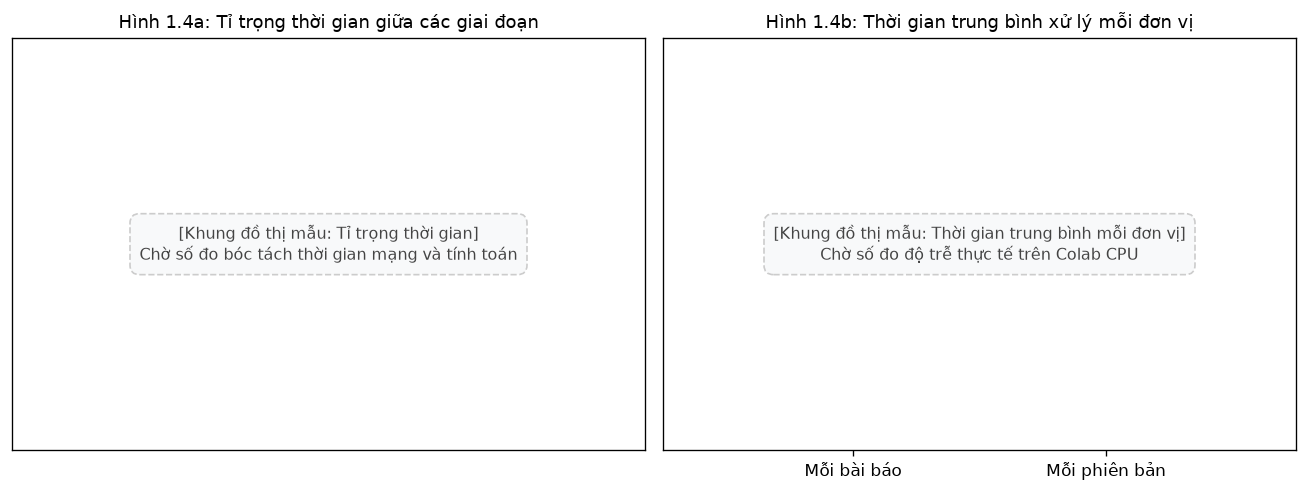

In [2]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2), dpi=120)

if is_placeholder or t_metrics["total_end_to_end_wall_time_seconds"] is None:
    ax1.text(0.5, 0.5, "[Khung đồ thị mẫu: Tỉ trọng thời gian]\nChờ số đo bóc tách thời gian mạng và tính toán",
             ha="center", va="center", fontsize=9.5, color="#444444",
             bbox=dict(boxstyle="round,pad=0.6", facecolor="#f8f9fa", edgecolor="#cccccc", linestyle="--"))
    ax1.set_xlim(0, 1)
    ax1.set_ylim(0, 1)
    ax1.set_yticks([])
    ax1.set_xticks([])
    
    ax2.text(0.5, 0.5, "[Khung đồ thị mẫu: Thời gian trung bình mỗi đơn vị]\nChờ số đo độ trễ thực tế trên Colab CPU",
             ha="center", va="center", fontsize=9.5, color="#444444",
             bbox=dict(boxstyle="round,pad=0.6", facecolor="#f8f9fa", edgecolor="#cccccc", linestyle="--"))
    ax2.set_xlim(0, 1)
    ax2.set_ylim(0, 1)
    ax2.set_yticks([])
    ax2.set_xticks([0.3, 0.7])
    ax2.set_xticklabels(["Mỗi bài báo", "Mỗi phiên bản"])
else:
    disc_time_h = t_metrics["discovery_total_wall_time_seconds"] / 3600
    crawl_time_h = t_metrics["crawl_total_wall_time_seconds"] / 3600
    labels = ["Khám phá bài báo", "Tải mã nguồn TeX và Semantic Scholar"]
    times = [disc_time_h, crawl_time_h]
    ax1.pie(times, labels=labels, autopct="%1.1f%%", startangle=140, colors=["#e7298a", "#1b9e77"], explode=(0.05, 0), textprops={"fontsize": 9})
    
    t_categories = ["Mỗi bài báo", "Mỗi phiên bản"]
    t_vals = [t_metrics["avg_wall_time_per_paper_seconds"], t_metrics["avg_wall_time_per_version_seconds"]]
    ax2.bar(t_categories, t_vals, color=["#377eb8", "#4daf4a"], width=0.45, edgecolor="black", linewidth=0.5)
    ax2.set_ylabel("Giây", fontsize=10)

ax1.set_title("Hình 1.4a: Tỉ trọng thời gian giữa các giai đoạn", fontsize=11)
ax2.set_title("Hình 1.4b: Thời gian trung bình xử lý mỗi đơn vị", fontsize=11)
plt.tight_layout()
plt.show()


## 3. Mức dùng bộ nhớ RAM và ổ đĩa

Bộ thu thập tải gói nén về vùng nhớ tạm có kiểm soát dung lượng, chỉ giữ lại các tệp `.tex` và `.bib` hợp lệ sang kho dữ liệu và lưu thống kê lấy mẫu dạng cuốn chiếu (streaming summary) nên không làm phình bộ nhớ RAM theo số lượng bài báo.


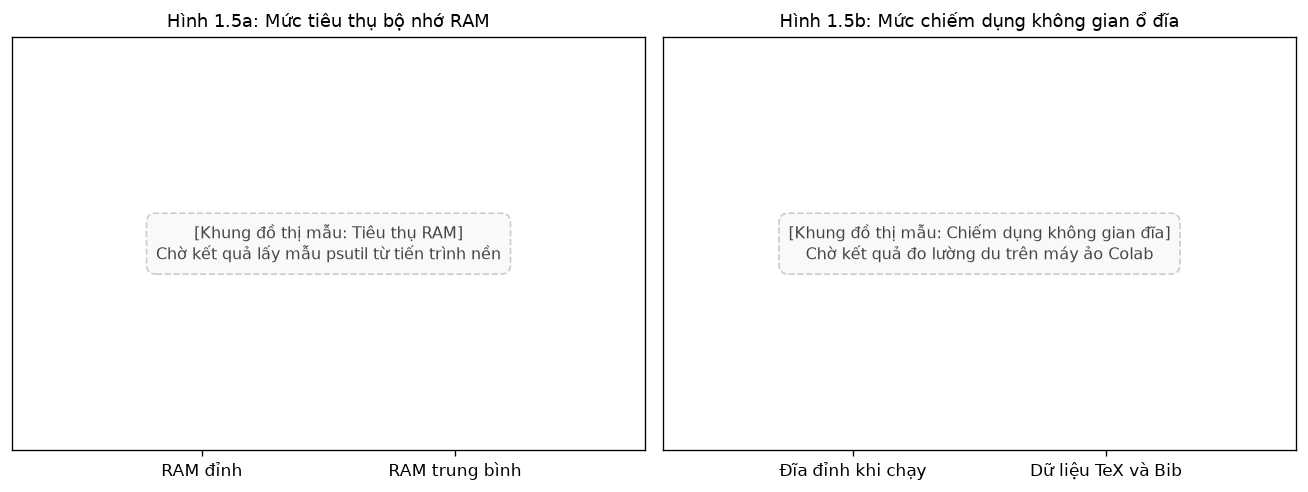

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2), dpi=120)

if is_placeholder or m_metrics["peak_ram_mb"] is None:
    ax1.text(0.5, 0.5, "[Khung đồ thị mẫu: Tiêu thụ RAM]\nChờ kết quả lấy mẫu psutil từ tiến trình nền",
             ha="center", va="center", fontsize=9.5, color="#444444",
             bbox=dict(boxstyle="round,pad=0.6", facecolor="#f8f9fa", edgecolor="#cccccc", linestyle="--"))
    ax1.set_xlim(0, 1)
    ax1.set_ylim(0, 1)
    ax1.set_yticks([])
    ax1.set_xticks([0.3, 0.7])
    ax1.set_xticklabels(["RAM đỉnh", "RAM trung bình"])
    
    ax2.text(0.5, 0.5, "[Khung đồ thị mẫu: Chiếm dụng không gian đĩa]\nChờ kết quả đo lường du trên máy ảo Colab",
             ha="center", va="center", fontsize=9.5, color="#444444",
             bbox=dict(boxstyle="round,pad=0.6", facecolor="#f8f9fa", edgecolor="#cccccc", linestyle="--"))
    ax2.set_xlim(0, 1)
    ax2.set_ylim(0, 1)
    ax2.set_yticks([])
    ax2.set_xticks([0.3, 0.7])
    ax2.set_xticklabels(["Đĩa đỉnh khi chạy", "Dữ liệu TeX và Bib"])
else:
    ram_labels = ["RAM đỉnh", "RAM trung bình"]
    ram_vals = [m_metrics["peak_ram_mb"], m_metrics["avg_ram_mb"]]
    ax1.bar(ram_labels, ram_vals, color=["#e41a1c", "#ff7f00"], width=0.45, edgecolor="black", linewidth=0.5)
    ax1.set_ylabel("Dung lượng (MB)", fontsize=10)
    
    disk_labels = ["Đĩa đỉnh khi chạy", "Dữ liệu TeX và Bib"]
    disk_vals = [s_metrics["max_disk_usage_gb"], s_metrics["final_corpus_output_gb"]]
    ax2.bar(disk_labels, disk_vals, color=["#984ea3", "#4daf4a"], width=0.45, edgecolor="black", linewidth=0.5)
    ax2.set_ylabel("Dung lượng (GB)", fontsize=10)

ax1.set_title("Hình 1.5a: Mức tiêu thụ bộ nhớ RAM", fontsize=11)
ax2.set_title("Hình 1.5b: Mức chiếm dụng không gian ổ đĩa", fontsize=11)
plt.tight_layout()
plt.show()


### Nhận xét về bộ nhớ và tài nguyên lưu trữ

- Mức RAM đỉnh trong quá trình chạy đạt `[Chờ số liệu Colab]` MB, với mức tiêu thụ RAM trung bình đo qua tiến trình nền là `[Chờ số liệu Colab]` MB. Kết quả này cho thấy bộ thu thập giải phóng bộ nhớ ngay sau từng bài báo, không xuất hiện hiện tượng rò rỉ bộ nhớ khi chạy dài hạn qua nhiều phiên.
- Mức dùng đĩa tối đa đạt `[Chờ số liệu Colab]` GB tại thời điểm giải nén tạm trong thư mục làm việc. Sau khi lọc bỏ toàn bộ tệp ảnh và chỉ giữ lại mã nguồn TeX và BibTeX, dung lượng lưu trữ thực tế còn lại là `[Chờ số liệu Colab]` GB, nằm trong hạn mức dung lượng của Google Colab và Google Drive.


## 4. Giới hạn thực nghiệm và bài học tối ưu hóa

- Kiểm soát tốc độ là giới hạn vật lý: Tốc độ thu thập dữ liệu bị chặn dưới bởi quy định 3,0 giây mỗi yêu cầu từ phía arXiv. Do đó, giải pháp tối ưu hóa khả thi nhất là xử lý gối đầu (song song hóa việc giải nén và bóc tách tệp trong khi chờ yêu cầu mạng tiếp theo) thay vì cố gắng tăng số lượng yêu cầu đồng thời.
- Vai trò của điểm kiểm soát bền vững: Việc lưu tệp trạng thái bền vững sau từng bài báo là điều kiện tiên quyết để hoàn thành bài toán 20.000 bài trên hạ tầng Colab miễn phí vốn thường xuyên bị ngắt phiên sau vài giờ.
- Lọc dữ liệu trên luồng đọc: Giải pháp lọc bỏ tệp ảnh trực tiếp trong luồng giải nén giúp tiết kiệm đáng kể băng thông ghi đĩa và giảm thiểu nguy cơ làm tràn bộ nhớ lưu trữ của máy ảo.
